# DDS-8555 Assignment 3: Build Non-Linear Models, Part 1 (Subset Selection, Regularization, and PCR)
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all. Approve the Google Drive prompt. The two Kaggle submission files download automatically and are also saved to Drive → DDS8555 → output.

| Section | What it covers |
|---|---|
| Textbook conceptual question (ISLP Ch. 6, Q1) | Part 1 |
| Textbook applied question (ISLP Ch. 6, Q8) | Part 2 |
| Kaggle model 1 (lasso) | Part 3, Model 1 |
| Kaggle model 2 (principal components regression) | Part 3, Model 2 |
| Regularized regression | Part 3, Model 1 (lasso; ridge for comparison) |
| Kaggle submission evidence | Screenshot in the paper's appendix |
| Code | This notebook (also on GitHub) |

In [1]:
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, warnings
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/DDS8555/abalone"
    OUT_DIR = "/content/drive/MyDrive/DDS8555/output"
    !pip -q install --no-deps ISLP
else:
    DATA_DIR = os.environ.get("DDS8555_DATA", "data")
    OUT_DIR = os.environ.get("DDS8555_OUT", "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from ISLP import load_data
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 44.3 MB/s eta 0:00:00


## Part 1. Conceptual Question 1 (ISLP Chapter 6)
*Paraphrased:* best subset, forward stepwise, and backward stepwise selection are each run on one data set, giving p + 1 models of sizes 0 through p.

**(a) Smallest training RSS with k predictors: best subset.** Best subset searches every k-predictor model, so its training RSS can be no larger than either stepwise method's. The stepwise methods search only a path of models, though they can tie with best subset.

**(b) Smallest test RSS with k predictors: it cannot be known in advance.** Best subset is most likely to win because it fits the training data best. It is also the most prone to overfitting, so either stepwise model can have lower test RSS, especially when n is small relative to p.

**(c) True or false:**
1. Forward k-model ⊂ forward (k+1)-model: **True.** Forward selection adds one predictor at a time and never removes one.
2. Backward k-model ⊂ backward (k+1)-model: **True.** Backward selection removes one predictor at a time, so the k-model is the (k+1)-model minus one predictor.
3. Backward k-model ⊂ forward (k+1)-model: **False.** The two paths are built independently and need not nest.
4. Forward k-model ⊂ backward (k+1)-model: **False**, for the same reason.
5. Best subset k-model ⊂ best subset (k+1)-model: **False.** Each size is searched separately, so the best pair need not contain the best single predictor.

## Part 2. Applied Question 8 (ISLP Chapter 6): simulated data
(a) Draw X and noise ε, with n = 100 each. (b) Y = β0 + β1X + β2X² + β3X³ + ε, with β = (3, 2, −3, 0.3). (c) Run forward stepwise and best subset selection over X, …, X¹⁰ and choose a model by Cp, BIC, and adjusted R². (d) Run backward stepwise selection. (e) Fit a lasso with cross-validated λ. (f) Repeat with Y = β0 + β7X⁷ + ε.

(c) Best subset: size chosen by Cp=4, BIC=4, adjR2=4
   Cp model: {'Intercept': np.float64(3.023), 'X1': np.float64(2.032), 'X2': np.float64(-3.19), 'X5': np.float64(0.125), 'X9': np.float64(-0.002)}
(c) Forward: size chosen by Cp=4, BIC=4, adjR2=4
   Cp model: {'Intercept': np.float64(3.053), 'X2': np.float64(-3.241), 'X1': np.float64(1.776), 'X3': np.float64(0.412), 'X10': np.float64(0.0)}
(d) Backward: size chosen by Cp=5, BIC=5, adjR2=5
   Cp model: {'Intercept': np.float64(3.005), 'X1': np.float64(2.146), 'X2': np.float64(-3.117), 'X6': np.float64(-0.075), 'X7': np.float64(0.018), 'X8': np.float64(0.016)}


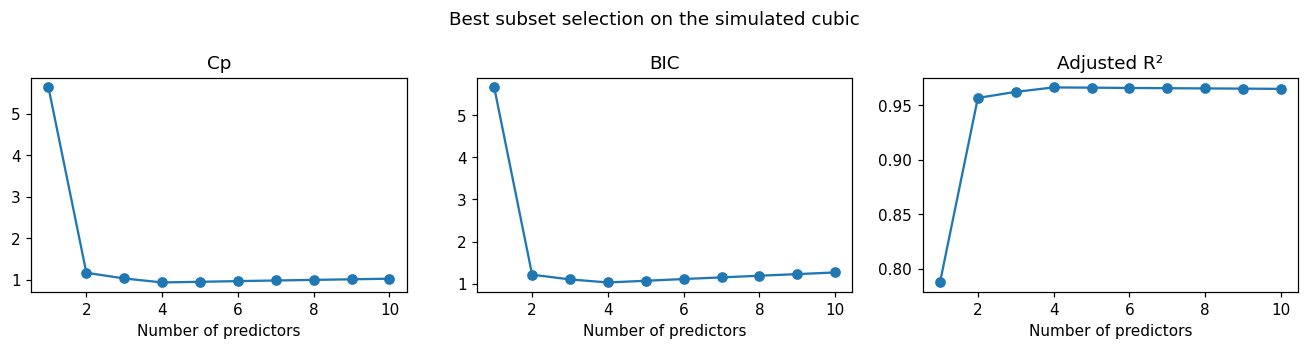

In [2]:
from itertools import combinations
from sklearn.linear_model import LassoCV, Lasso, RidgeCV, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(1)
n = 100
x = rng.normal(size=n); eps = rng.normal(size=n)
P = pd.DataFrame({f"X{k}": x ** k for k in range(1, 11)})

def ols_rss(cols, Y):
    A = np.column_stack([np.ones(len(Y))] + [P[c].values for c in cols])
    beta, *_ = np.linalg.lstsq(A, Y, rcond=None)
    return float(((Y - A @ beta) ** 2).sum()), beta

def criteria(cols, Y, sigma2):
    rss, beta = ols_rss(cols, Y); d = len(cols); tss = ((Y - Y.mean()) ** 2).sum()
    return {"cp": (rss + 2 * d * sigma2) / len(Y),
            "bic": (rss + np.log(len(Y)) * d * sigma2) / len(Y),
            "adjr2": 1 - (rss / (len(Y) - d - 1)) / (tss / (len(Y) - 1)), "rss": rss, "beta": beta}

def best_subset(Y):
    best = {}
    for k in range(1, 11):
        best[k] = min(combinations(P.columns, k), key=lambda c: ols_rss(c, Y)[0])
    return best

def forward(Y):
    chosen, path = [], {}
    for k in range(1, 11):
        add = min([c for c in P.columns if c not in chosen], key=lambda c: ols_rss(chosen + [c], Y)[0])
        chosen = chosen + [add]; path[k] = tuple(chosen)
    return path

def backward(Y):
    cur, path = list(P.columns), {10: tuple(P.columns)}
    for k in range(9, 0, -1):
        drop = min(cur, key=lambda c: ols_rss([v for v in cur if v != c], Y)[0])
        cur = [v for v in cur if v != drop]; path[k] = tuple(cur)
    return path

def pick(path, Y):
    sigma2 = ols_rss(list(P.columns), Y)[0] / (len(Y) - 11)       # full-model error variance
    tab = pd.DataFrame({k: criteria(path[k], Y, sigma2) for k in path}).T
    out = {"Cp": int(tab.cp.astype(float).idxmin()), "BIC": int(tab.bic.astype(float).idxmin()),
           "adjR2": int(tab.adjr2.astype(float).idxmax())}
    return out, tab

def report(name, path, Y):
    sel, tab = pick(path, Y)
    k = sel["Cp"]; _, beta = ols_rss(path[k], Y)
    print(f"{name}: size chosen by Cp={sel['Cp']}, BIC={sel['BIC']}, adjR2={sel['adjR2']}")
    print("   Cp model:", dict(zip(["Intercept"] + list(path[k]), np.round(beta, 3))))
    return sel, tab

Y = 3 + 2 * x - 3 * x ** 2 + 0.3 * x ** 3 + eps
bs, fw, bw = best_subset(Y), forward(Y), backward(Y)
sel_bs, tab_bs = report("(c) Best subset", bs, Y)
sel_fw, tab_fw = report("(c) Forward", fw, Y)
sel_bw, tab_bw = report("(d) Backward", bw, Y)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, col, lab in zip(ax, ["cp", "bic", "adjr2"], ["Cp", "BIC", "Adjusted R²"]):
    a.plot(tab_bs.index, tab_bs[col].astype(float), "o-"); a.set_xlabel("Number of predictors"); a.set_title(lab)
plt.suptitle("Best subset selection on the simulated cubic"); plt.tight_layout(); plt.show()

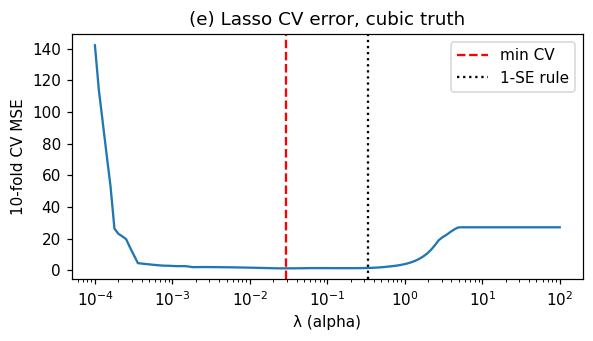

min-CV λ = 0.0296: nonzero terms {'X1': 1.856, 'X2': -3.164, 'X3': 0.357, 'X10': 0.0}
1-SE λ = 0.3384: nonzero terms {'X1': 1.862, 'X2': -2.848, 'X3': 0.218}
(f) Forward, X^7 truth: size chosen by Cp=3, BIC=2, adjR2=3
   Cp model: {'Intercept': np.float64(2.969), 'X7': np.float64(1.016), 'X9': np.float64(-0.003), 'X4': np.float64(-0.042)}
(f) Best subset, X^7 truth: size chosen by Cp=3, BIC=2, adjR2=3
   Cp model: {'Intercept': np.float64(2.97), 'X6': np.float64(-0.049), 'X7': np.float64(1.004), 'X8': np.float64(0.009)}


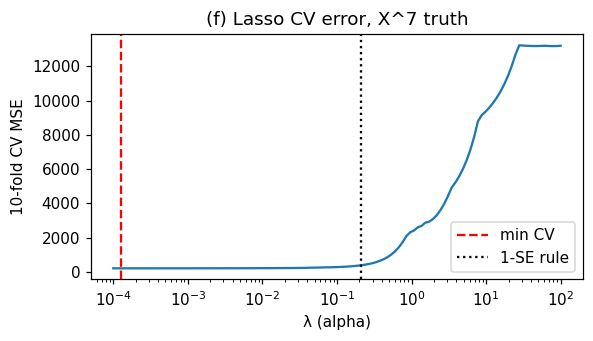

min-CV λ = 0.0001: nonzero terms {'X1': 1.813, 'X2': -0.786, 'X3': -4.991, 'X4': 0.663, 'X5': 3.202, 'X6': -0.079, 'X7': 0.366, 'X8': -0.008, 'X9': 0.034, 'X10': -0.001}
1-SE λ = 0.2127: nonzero terms {'X5': 0.285, 'X6': -0.005, 'X7': 0.906, 'X9': 0.007}


In [3]:
def lasso_fit(Y, title):
    """Lasso with 10-fold CV. Reports both the minimum-CV λ and the one-standard-error λ
    (the largest λ whose CV error is within one SE of the minimum, which gives a sparser model)."""
    scaler = StandardScaler().fit(P); Z = scaler.transform(P)
    lcv = LassoCV(cv=10, alphas=np.logspace(-4, 2, 120), max_iter=500000).fit(Z, Y)
    mse = lcv.mse_path_.mean(axis=1); se = lcv.mse_path_.std(axis=1) / np.sqrt(10)
    i = mse.argmin(); a1se = float(lcv.alphas_[mse <= mse[i] + se[i]].max())
    plt.figure(figsize=(5.5, 3.2)); plt.semilogx(lcv.alphas_, mse)
    plt.axvline(lcv.alpha_, ls="--", c="r", label="min CV"); plt.axvline(a1se, ls=":", c="k", label="1-SE rule")
    plt.xlabel("λ (alpha)"); plt.ylabel("10-fold CV MSE"); plt.title(title); plt.legend(); plt.tight_layout(); plt.show()
    out = {}
    for lab, a in (("min-CV", lcv.alpha_), ("1-SE", a1se)):
        coef = pd.Series(Lasso(alpha=a, max_iter=500000).fit(Z, Y).coef_ / scaler.scale_, index=P.columns)
        nz = coef[coef.abs() > 1e-8]
        print(f"{lab} λ = {a:.4f}: nonzero terms {nz.round(3).to_dict()}")
        out[lab] = list(nz.index)
    return out

las_e = lasso_fit(Y, "(e) Lasso CV error, cubic truth")

Y7 = 3 + 1.0 * x ** 7 + eps
fw7 = forward(Y7); bs7 = best_subset(Y7)
sel_fw7, _ = report("(f) Forward, X^7 truth", fw7, Y7)
sel_bs7, _ = report("(f) Best subset, X^7 truth", bs7, Y7)
las_f = lasso_fit(Y7, "(f) Lasso CV error, X^7 truth")
RESULTS["sim"] = {"bs": sel_bs, "fw": sel_fw, "bw": sel_bw,
                  "bs_terms": list(bs[sel_bs["Cp"]]), "fw_terms": list(fw[sel_fw["Cp"]]), "bw_terms": list(bw[sel_bw["Cp"]]),
                  "lasso_e": las_e, "lasso_f": las_f, "fw7_terms": list(fw7[sel_fw7["Cp"]]),
                  "bs7_terms": list(bs7[sel_bs7["Cp"]])}

**Reading Part 2** (seeded, so the results match on every run).
* **(c)–(d)** The truth is X, X², X³ with a small cubic coefficient (0.3). All three methods keep X and X². Forward selection recovers X³. Best subset and backward selection substitute other odd or even powers (X⁵, X⁶ to X⁹) that mimic the weak cubic term, and they add a nearly-zero high power. These alternatives are almost collinear with the true terms, so with n = 100 the data barely distinguish them. Cp, BIC, and adjusted R² agree on the model size here.
* **(e)** With λ at the minimum CV error, the lasso keeps X, X², X³ and a negligible X¹⁰. With the one-standard-error rule, it keeps **exactly X, X², X³**, with coefficients close to the truth but shrunk toward zero (the cubic most).
* **(f)** With a single true X⁷ term, forward selection and best subset both put a coefficient near 1.0 on X⁷ and add tiny neighbors. The minimum-CV lasso picks a very small λ and keeps all ten powers, because the standardized odd powers are almost collinear and a few extreme x values dominate the CV error. The one-standard-error λ recovers essentially **X⁷ alone**. Lesson: on collinear features, the minimum-CV λ optimizes prediction rather than selection, so the one-SE rule is the better tool when the goal is a sparse model.

## Kaggle data: Regression with an Abalone Dataset (Playground Series S4E4)
The data load and cleaning cell is identical in Assignments 2, 3, and 4, so the three notebooks use the same data.
Put the Kaggle download (the zip, or `train.csv`, `test.csv`, `sample_submission.csv`) in **Google Drive → My Drive → DDS8555 → abalone**. If the files are not there, an upload button appears.

**Cleaning rule (kept the same in A2–A4):** a height of 0 is physically impossible, so it is treated as missing and replaced with the training-set median height for that sex. Nothing else is changed. The target is modeled as log(1 + Rings) because the competition is scored by RMSLE (root mean squared logarithmic error).

In [4]:
# ---- Load and clean the Kaggle abalone data (same cell in A2, A3, A4) ----
for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(z) as f:
        f.extractall(DATA_DIR)
NEED = ["train.csv", "test.csv", "sample_submission.csv"]
if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in NEED):
    print("Choose the Kaggle zip (or the three CSV files):")
    for name, data in files.upload().items():
        open(os.path.join(DATA_DIR, name), "wb").write(data)
    for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
        zipfile.ZipFile(z).extractall(DATA_DIR)
missing = [f for f in NEED if not os.path.exists(os.path.join(DATA_DIR, f))]
assert not missing, f"Missing files in {DATA_DIR}: {missing}"

RENAME = {"whole weight": "whole_wt", "whole weight.1": "shucked_wt", "whole weight.2": "viscera_wt",
          "shucked weight": "shucked_wt", "viscera weight": "viscera_wt", "shell weight": "shell_wt",
          "whole_weight": "whole_wt", "shucked_weight": "shucked_wt", "viscera_weight": "viscera_wt",
          "shell_weight": "shell_wt"}
tidy = lambda d: d.rename(columns=lambda c: RENAME.get(c.strip().lower(), c.strip().lower()))
train_raw = tidy(pd.read_csv(os.path.join(DATA_DIR, "train.csv")))
test_raw = tidy(pd.read_csv(os.path.join(DATA_DIR, "test.csv")))
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
NUM = ["length", "diameter", "height", "whole_wt", "shucked_wt", "viscera_wt", "shell_wt"]
print("train:", train_raw.shape, " test:", test_raw.shape)
print("columns:", list(train_raw.columns))

HEIGHT_MED = train_raw.loc[train_raw.height > 0].groupby("sex")["height"].median()

def prepare(df):
    """Impute impossible zero heights; one-hot Sex with F as the baseline."""
    out = df.copy()
    zero = out["height"] <= 0
    out.loc[zero, "height"] = out.loc[zero, "sex"].map(HEIGHT_MED)
    sex = pd.Categorical(out["sex"], categories=["F", "I", "M"])
    X = pd.concat([out[NUM].astype(float),
                   pd.get_dummies(sex, prefix="sex", drop_first=True, dtype=float).set_index(out.index)], axis=1)
    return X, int(zero.sum())

X, zero_tr = prepare(train_raw)
X_test, zero_te = prepare(test_raw)
y = train_raw["rings"].astype(float)
ylog = np.log1p(y)
print(f"missing values: train {int(train_raw.isna().sum().sum())}, test {int(test_raw.isna().sum().sum())}")
print(f"zero heights imputed: train {zero_tr}, test {zero_te}")
print(f"duplicate rows (excluding id): {int(train_raw.drop(columns='id').duplicated().sum())}")
print("sex counts:", train_raw["sex"].value_counts().to_dict())
print(train_raw[NUM + ["rings"]].describe().T.round(3))
RESULTS["data"] = {"n_train": int(len(X)), "n_test": int(len(X_test)), "zero_height_train": zero_tr,
                   "zero_height_test": zero_te, "missing_train": int(train_raw.isna().sum().sum()),
                   "rings_min": float(y.min()), "rings_max": float(y.max()),
                   "rings_mean": float(y.mean()), "rings_skew": float(y.skew())}

# ---- Shared scoring helpers ----
from sklearn.model_selection import KFold, cross_val_predict
KF = KFold(n_splits=5, shuffle=True, random_state=42)
LO, HI = float(y.min()), float(y.max())

def rmsle(y_true, y_pred):
    return float(np.sqrt(np.mean((np.log1p(y_true) - np.log1p(y_pred)) ** 2)))

def cv_rmsle(model, XX, target="log"):
    """5-fold CV RMSLE on the training set. target='log' fits log1p(Rings)."""
    t = ylog if target == "log" else y
    p = cross_val_predict(model, XX, t, cv=KF)
    p = np.expm1(p) if target == "log" else p
    return rmsle(y, np.clip(p, LO, HI))

def write_submission(pred, name):
    sub = pd.DataFrame({sample.columns[0]: test_raw["id"].values,
                        sample.columns[1]: np.clip(pred, LO, HI)})
    path = os.path.join(OUT_DIR, name)
    sub.to_csv(path, index=False)
    print("saved", path, sub.shape)
    if IN_COLAB:
        files.download(path)
    return path

def resid_panel(fitted, resid, title, ax_row):
    ax1, ax2 = ax_row
    ax1.scatter(fitted, resid, s=2, alpha=.25)
    ax1.axhline(0, color="k", lw=.8)
    ax1.set_xlabel("Fitted value"); ax1.set_ylabel("Residual"); ax1.set_title(title + ": residuals vs fitted")
    sm.qqplot(resid, line="s", ax=ax2, markersize=2, alpha=.3)
    ax2.set_title(title + ": normal Q-Q")

def diagnostics(resid, exog):
    """Breusch-Pagan, Durbin-Watson, Jarque-Bera on a fitted model's residuals."""
    bp = het_breuschpagan(resid, sm.add_constant(exog, has_constant="add"))
    jb = jarque_bera(resid)
    return {"bp_stat": float(bp[0]), "bp_p": float(bp[1]), "dw": float(durbin_watson(resid)),
            "jb_stat": float(jb[0]), "skew": float(jb[2]), "kurtosis": float(jb[3])}

train: (90615, 10)  test: (60411, 9)
columns: ['id', 'sex', 'length', 'diameter', 'height', 'whole_wt', 'shucked_wt', 'viscera_wt', 'shell_wt', 'rings']
missing values: train 0, test 0
zero heights imputed: train 6, test 2
duplicate rows (excluding id): 0
sex counts: {'I': 33093, 'M': 31027, 'F': 26495}
              count   mean    std    min    25%    50%     75%     max
length      90615.0  0.517  0.118  0.075  0.445  0.545   0.600   0.815
diameter    90615.0  0.402  0.098  0.055  0.345  0.425   0.470   0.650
height      90615.0  0.135  0.038  0.000  0.110  0.140   0.160   1.130
whole_wt    90615.0  0.789  0.458  0.002  0.419  0.800   1.068   2.826
shucked_wt  90615.0  0.341  0.204  0.001  0.178  0.330   0.463   1.488
viscera_wt  90615.0  0.169  0.101  0.000  0.086  0.166   0.232   0.760
shell_wt    90615.0  0.226  0.130  0.002  0.120  0.225   0.305   1.005
rings       90615.0  9.697  3.176  1.000  8.000  9.000  11.000  29.000


## Part 3. Kaggle models
**Model 1: lasso on an expanded feature set, used to guide subset selection.** The candidate features are the 9 base predictors, the 7 squared measurements, all 21 pairwise products of measurements, and 14 Sex × measurement interactions, 51 in total. All are standardized. The lasso penalty sets weak features to exactly zero; the surviving features are the lasso-selected subset. λ comes from 5-fold CV on log(1 + Rings) with the **one-standard-error rule** (the largest λ whose CV error is within one SE of the minimum), because with about 90,000 rows the minimum-CV λ is so small that the lasso barely differs from OLS. This is the same lesson as Part 2 (f). For comparison, exhaustive best subset selection over the 9 base predictors (511 models) is ranked by BIC, a ridge model is fit, and OLS is refit on the lasso subset.

**Model 2: principal components regression (PCR).** The 9 base predictors are standardized and replaced by their principal components, and OLS is fit on the first *M* components. *M* is chosen by 5-fold CV. Because PCR regresses on uncorrelated components, it is a direct answer to the collinearity found in Assignment 2.

expanded features: 51
min-CV λ = 0.000010 keeps 46 features; one-SE λ = 0.000127 keeps 25 of 51
shell_wt               0.3819
shucked_wt            -0.3773
whole_wt               0.2390
shucked_wt^2           0.2388
length                 0.1777
length^2              -0.1542
length*diameter       -0.1291
height                 0.1049
height*shucked_wt     -0.0926
diameter               0.0779
shucked_wt*shell_wt   -0.0751
shell_wt^2            -0.0434
sex_I                 -0.0412
sex_I*shucked_wt       0.0399
viscera_wt*shell_wt   -0.0393
whole_wt*shell_wt     -0.0389
whole_wt^2            -0.0342
length*shucked_wt     -0.0305
height^2              -0.0179
sex_I*shell_wt        -0.0134
sex_I*height          -0.0123
sex_M                 -0.0036
sex_M*whole_wt         0.0029
sex_I*viscera_wt       0.0006
diameter*shucked_wt   -0.0002


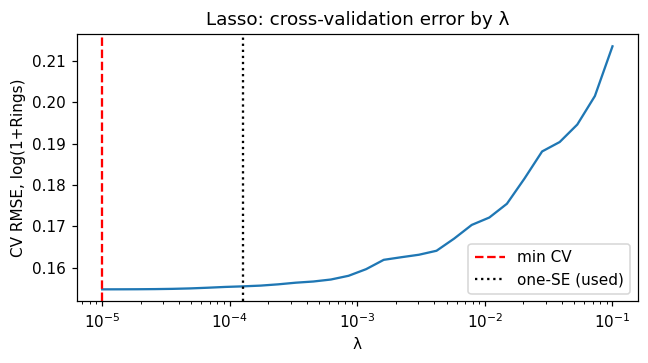


Best subset (BIC) over base predictors: 8 predictors -> ['length', 'diameter', 'height', 'whole_wt', 'shucked_wt', 'viscera_wt', 'shell_wt', 'sex_I']
base predictors appearing in any lasso-kept feature: ['diameter', 'height', 'length', 'sex_I', 'sex_M', 'shell_wt', 'shucked_wt', 'viscera_wt', 'whole_wt']


In [5]:
def expand(D):
    E = D.copy()
    for c in NUM:
        E[c + "^2"] = D[c] ** 2
    for a, b in combinations(NUM, 2):
        E[a + "*" + b] = D[a] * D[b]
    for s in ["sex_I", "sex_M"]:
        for c in NUM:
            E[s + "*" + c] = D[s] * D[c]
    return E
XE, XE_test = expand(X), expand(X_test)
print("expanded features:", XE.shape[1])

# Lasso path with 5-fold CV. With ~90,000 rows the minimum-CV penalty is tiny (almost OLS), so the
# one-standard-error rule picks the penalty: the sparsest model whose CV error is within one SE of the minimum.
sc = StandardScaler().fit(XE); ZE = sc.transform(XE)
lcv = LassoCV(cv=KF, alphas=np.logspace(-5, -1, 30), max_iter=5000, tol=1e-3).fit(ZE, ylog)
mse = lcv.mse_path_.mean(axis=1); se = lcv.mse_path_.std(axis=1) / np.sqrt(KF.get_n_splits())
i_min = int(mse.argmin()); alpha_1se = float(lcv.alphas_[mse <= mse[i_min] + se[i_min]].max())
lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha_1se, max_iter=5000, tol=1e-3)).fit(XE, ylog)
coef = pd.Series(lasso[-1].coef_, index=XE.columns)
kept = list(coef[coef.abs() > 1e-10].index)
n_kept_min = int((np.abs(Lasso(alpha=lcv.alpha_, max_iter=5000, tol=1e-3).fit(ZE, ylog).coef_) > 1e-10).sum())
print(f"min-CV λ = {lcv.alpha_:.6f} keeps {n_kept_min} features; one-SE λ = {alpha_1se:.6f} keeps {len(kept)} of {XE.shape[1]}")
print(coef[kept].sort_values(key=np.abs, ascending=False).round(4).to_string())

plt.figure(figsize=(6, 3.4))
plt.semilogx(lcv.alphas_, np.sqrt(lcv.mse_path_.mean(axis=1)))
plt.axvline(lcv.alpha_, ls="--", c="r", label="min CV"); plt.axvline(alpha_1se, ls=":", c="k", label="one-SE (used)")
plt.legend(); plt.xlabel("λ"); plt.ylabel("CV RMSE, log(1+Rings)")
plt.title("Lasso: cross-validation error by λ"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "A3_fig_lasso_cv.png"), dpi=150); plt.show()

# Best subset over the 9 base predictors, ranked by BIC (on the log target)
n_tr = len(ylog); best_bic = []
for k in range(1, X.shape[1] + 1):
    rows = []
    for cols in combinations(X.columns, k):
        A = np.column_stack([np.ones(n_tr), X[list(cols)].values])
        beta, *_ = np.linalg.lstsq(A, ylog.values, rcond=None)
        rss = float(((ylog.values - A @ beta) ** 2).sum())
        rows.append((n_tr * np.log(rss / n_tr) + (k + 1) * np.log(n_tr), cols))
    best_bic.append(min(rows))
bic_best = min(best_bic)
print(f"\nBest subset (BIC) over base predictors: {len(bic_best[1])} predictors -> {list(bic_best[1])}")
base_in_lasso = sorted({c for c in X.columns if any(c == f or f.startswith(c) or f.endswith(c) for f in kept)})
print("base predictors appearing in any lasso-kept feature:", base_in_lasso)

   CV RMSLE  cum. variance
1   0.19841         0.7976
2   0.19841         0.9127
3   0.19642         0.9507
4   0.18236         0.9717
5   0.17475         0.9846
6   0.16482         0.9927
7   0.16468         0.9977
8   0.16422         0.9989
9   0.16420         1.0000
PCR: best M = 9; smallest M within 1% of best = 6
PC1 loadings: {'length': 0.36, 'diameter': 0.361, 'height': 0.351, 'whole_wt': 0.365, 'shucked_wt': 0.356, 'viscera_wt': 0.36, 'shell_wt': 0.358, 'sex_I': -0.276, 'sex_M': 0.149}


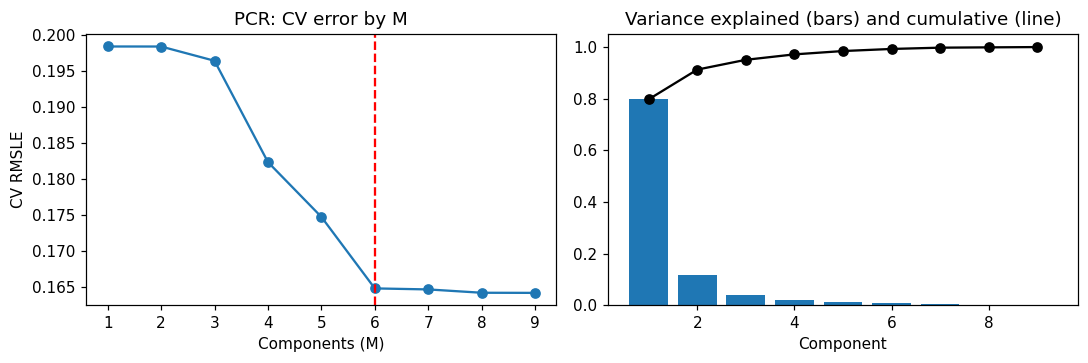

OLS, 9 base predictors (A2 baseline)    0.16420
Lasso, 51 features (Model 1)            0.15543
OLS refit on lasso subset               0.15518
Ridge, 51 features                      0.15468
PCR, M = 6 (Model 2)                    0.16482


In [6]:
from sklearn.decomposition import PCA
cv_lasso = cv_rmsle(make_pipeline(StandardScaler(), Lasso(alpha=alpha_1se, max_iter=5000, tol=1e-3)), XE)   # λ fixed from the CV above
cv_ridge = cv_rmsle(make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25))), XE)
cv_refit = cv_rmsle(LinearRegression(), XE[kept])
cv_base = cv_rmsle(LinearRegression(), X)

pcr_scores = {}
for M in range(1, X.shape[1] + 1):
    pcr_scores[M] = cv_rmsle(make_pipeline(StandardScaler(), PCA(n_components=M), LinearRegression()), X)
pcr_tab = pd.Series(pcr_scores, name="CV RMSLE")
# Smallest M within 1% of the best score (one-standard-error spirit: prefer fewer components)
M_best = int(pcr_tab.idxmin()); M_pick = int(pcr_tab[pcr_tab <= pcr_tab.min() * 1.01].index.min())
pca_full = make_pipeline(StandardScaler(), PCA()).fit(X)[-1]
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
print(pd.DataFrame({"CV RMSLE": pcr_tab.round(5), "cum. variance": np.round(cumvar, 4)}))
print(f"PCR: best M = {M_best}; smallest M within 1% of best = {M_pick}")
print("PC1 loadings:", pd.Series(pca_full.components_[0], index=X.columns).round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(pcr_tab.index, pcr_tab.values, "o-"); ax[0].axvline(M_pick, ls="--", c="r")
ax[0].set_xlabel("Components (M)"); ax[0].set_ylabel("CV RMSLE"); ax[0].set_title("PCR: CV error by M")
ax[1].bar(range(1, len(cumvar) + 1), pca_full.explained_variance_ratio_); ax[1].plot(range(1, len(cumvar) + 1), cumvar, "o-k")
ax[1].set_xlabel("Component"); ax[1].set_title("Variance explained (bars) and cumulative (line)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A3_fig_pcr.png"), dpi=150); plt.show()

cmp = pd.Series({"OLS, 9 base predictors (A2 baseline)": cv_base, "Lasso, 51 features (Model 1)": cv_lasso,
                 "OLS refit on lasso subset": cv_refit, "Ridge, 51 features": cv_ridge,
                 f"PCR, M = {M_pick} (Model 2)": pcr_tab[M_pick]}, name="5-fold CV RMSLE")
print(cmp.round(5).to_string())

### Assumption checks for both submitted models
The lasso and PCR are both linear models fit by least squares (the lasso adds a penalty), so the same residual checks apply: residuals vs fitted values and a normal Q-Q plot for each, plus Breusch-Pagan, Durbin-Watson, and Jarque-Bera. Collinearity is handled by design. The lasso drops or shrinks redundant features, and PCR's components are uncorrelated by construction, so the VIF problem from Assignment 2 does not destabilize either model.

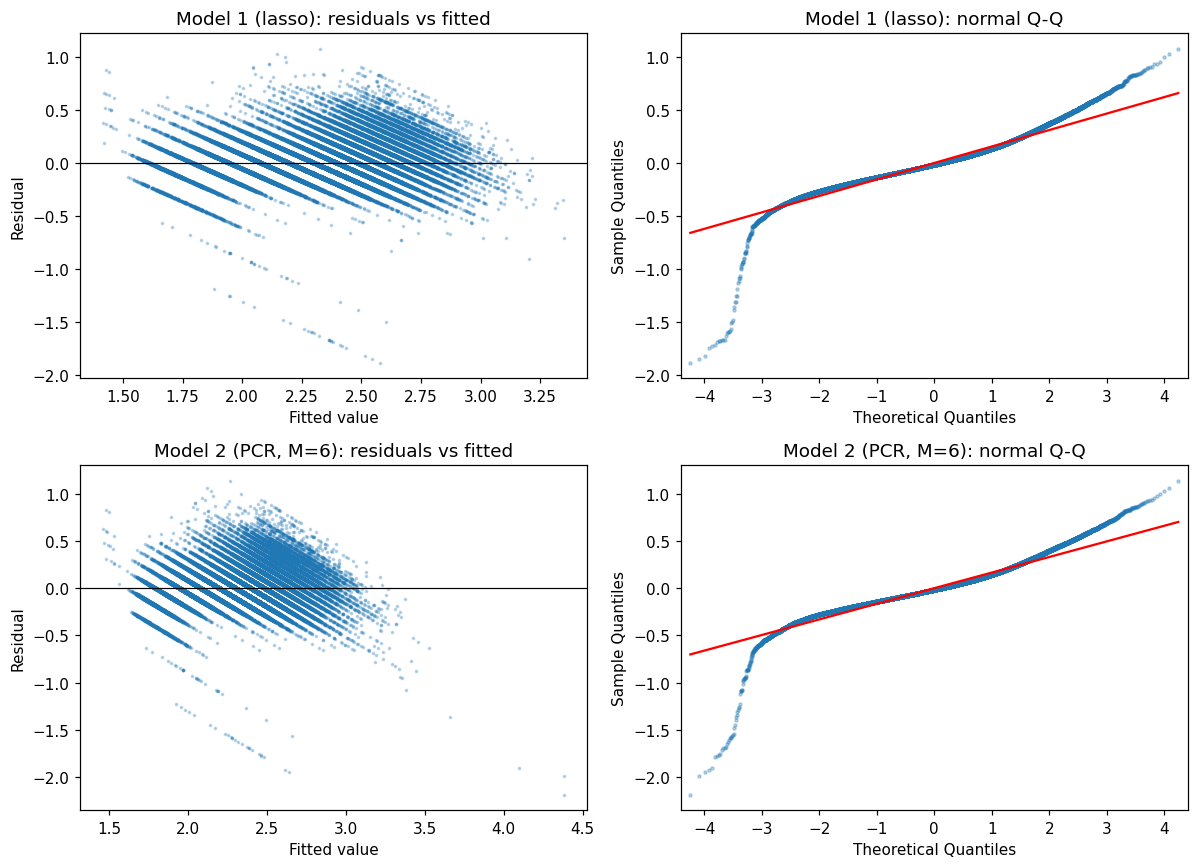

                   bp_stat  bp_p      dw      jb_stat    skew  kurtosis
Model 1 (lasso)  1984.8916   0.0  1.9994  111781.1006  0.3123    8.4052
Model 2 (PCR)    4613.8840   0.0  1.9935  112428.2738  0.2895    8.4261
saved /content/drive/MyDrive/DDS8555/output/A3_model1_lasso.csv (60411, 2)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A3_model2_pcr.csv (60411, 2)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
pcr = make_pipeline(StandardScaler(), PCA(n_components=M_pick), LinearRegression()).fit(X, ylog)
fit_l = lasso.predict(XE); fit_p = pcr.predict(X)
res_l = ylog - fit_l; res_p = ylog - fit_p
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
resid_panel(fit_l, res_l, "Model 1 (lasso)", ax[0]); resid_panel(fit_p, res_p, f"Model 2 (PCR, M={M_pick})", ax[1])
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A3_fig_residuals.png"), dpi=150); plt.show()
d_l = diagnostics(np.asarray(res_l), X); d_p = diagnostics(np.asarray(res_p), X)
print(pd.DataFrame({"Model 1 (lasso)": d_l, "Model 2 (PCR)": d_p}).T.round(4))

write_submission(np.expm1(lasso.predict(XE_test)), "A3_model1_lasso.csv")
write_submission(np.expm1(pcr.predict(X_test)), "A3_model2_pcr.csv")

RESULTS_FILE = "A3_results.json"
RESULTS["lasso"] = {"alpha_min": float(lcv.alpha_), "alpha_1se": alpha_1se, "n_kept_min": n_kept_min,
                    "n_features": int(XE.shape[1]), "n_kept": len(kept), "kept": kept,
                    "cv_rmsle": cv_lasso, **d_l}
RESULTS["ridge_cv"] = cv_ridge; RESULTS["refit_cv"] = cv_refit; RESULTS["base_cv"] = cv_base
RESULTS["bic_subset"] = list(bic_best[1])
RESULTS["pcr"] = {"M_best": M_best, "M_pick": M_pick, "cv_rmsle": float(pcr_tab[M_pick]), "cv_by_M": pcr_tab.to_dict(),
                  "cumvar": cumvar.tolist(), "pc1": pd.Series(pca_full.components_[0], index=X.columns).round(3).to_dict(), **d_p}

In [8]:
# ---- Plain-language reading of the results (printed from the numbers above) ----
print(f"* Lasso kept {len(kept)} of {XE.shape[1]} candidate features and reached CV RMSLE {cv_lasso:.4f}, "
      f"vs {cv_base:.4f} for plain OLS on the 9 base predictors ({'better' if cv_lasso < cv_base else 'no better'}).")
print(f"* Ridge on the same 51 features: {cv_ridge:.4f}; OLS refit on the lasso subset: {cv_refit:.4f}.")
print(f"* Best subset by BIC keeps {len(bic_best[1])} of 9 base predictors: {list(bic_best[1])}.")
print(f"* PCR: the first component alone explains {cumvar[0]:.0%} of predictor variance (an overall 'size' axis), "
      f"but CV error keeps falling until M = {M_best}; the smallest M within 1% of the best is {M_pick}. "
      "High-variance directions are not automatically the ones that predict age.")
best = min(cv_lasso, pcr_tab[M_pick])
print(f"* Better submitted model: {'lasso' if cv_lasso <= pcr_tab[M_pick] else 'PCR'} (CV RMSLE {best:.4f}).")

* Lasso kept 25 of 51 candidate features and reached CV RMSLE 0.1554, vs 0.1642 for plain OLS on the 9 base predictors (better).
* Ridge on the same 51 features: 0.1547; OLS refit on the lasso subset: 0.1552.
* Best subset by BIC keeps 8 of 9 base predictors: ['length', 'diameter', 'height', 'whole_wt', 'shucked_wt', 'viscera_wt', 'shell_wt', 'sex_I'].
* PCR: the first component alone explains 80% of predictor variance (an overall 'size' axis), but CV error keeps falling until M = 9; the smallest M within 1% of the best is 6. High-variance directions are not automatically the ones that predict age.
* Better submitted model: lasso (CV RMSLE 0.1554).


In [9]:
# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

RESULTS_JSON_START
{"sim": {"bs": {"Cp": 4, "BIC": 4, "adjR2": 4}, "fw": {"Cp": 4, "BIC": 4, "adjR2": 4}, "bw": {"Cp": 5, "BIC": 5, "adjR2": 5}, "bs_terms": ["X1", "X2", "X5", "X9"], "fw_terms": ["X2", "X1", "X3", "X10"], "bw_terms": ["X1", "X2", "X6", "X7", "X8"], "lasso_e": {"min-CV": ["X1", "X2", "X3", "X10"], "1-SE": ["X1", "X2", "X3"]}, "lasso_f": {"min-CV": ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8", "X9", "X10"], "1-SE": ["X5", "X6", "X7", "X9"]}, "fw7_terms": ["X7", "X9", "X4"], "bs7_terms": ["X6", "X7", "X8"]}, "data": {"n_train": 90615, "n_test": 60411, "zero_height_train": 6, "zero_height_test": 2, "missing_train": 0, "rings_min": 1.0, "rings_max": 29.0, "rings_mean": 9.696794129007339, "rings_skew": 1.2042729726026435}, "lasso": {"alpha_min": 1e-05, "alpha_1se": 0.0001268961003167922, "n_kept_min": 46, "n_features": 51, "n_kept": 25, "kept": ["length", "diameter", "height", "whole_wt", "shucked_wt", "shell_wt", "sex_I", "sex_M", "length^2", "height^2", "whole_wt^2", "s